 # Sprint 1: Formalización del problema

## Espacio de codificación de soluciones


In [3]:
from itertools import product
from CDP_graph import crear_grafo,visualizar_grafo
import community
import networkx as nx
import numpy as np
import random
from collections import defaultdict

## Codificación de soluciones


La codificacion que hemos elegido es un vector de enteros, 
donde cada entero representara el cluster al que pertenece el nodo que corresponde a esa posicion en el vector.

$$

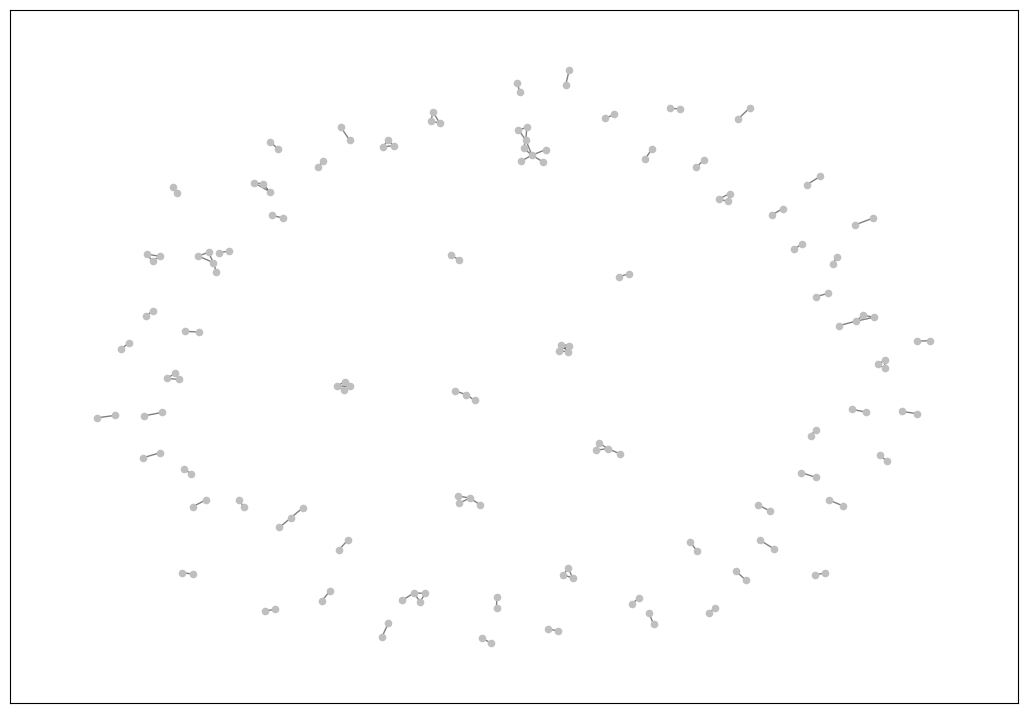

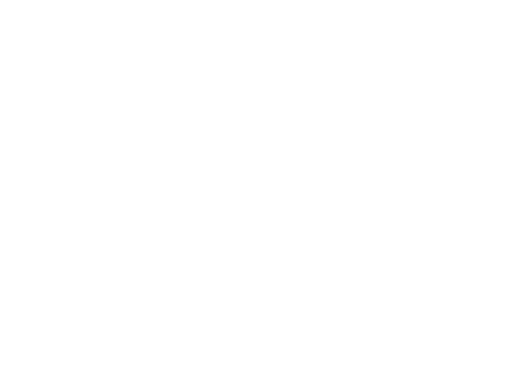

In [10]:
### Propón algunas soluciones al problema como ejemplo
sql = "C:/Users/HP/Downloads/database_50_sample.sqlite"
G = crear_grafo(sql)

n = G.number_of_nodes()
rng = random.Random(42)
#solución aleatoria
sol_1 = [rng.randrange(2) for _ in range(n)]
#cada nodo es un cluster
sol_2 = list(range(n))
sol_3=  [0] * n

#TODO: Interesante -> para fase2 solución inicial usando spectral clustering
#sol_3 =...



visualizar_grafo(G)

### Función objetivo


La función objetivo es maximizar la modularidad de la partición del grafo. La modularidad es una medida que evalúa la calidad de una partición en un grafo, comparando la densidad de los clústeres que están colocados en el interior con los clústeres que hacen frontera con otras comunidades.

La fórmula de la modularidad es la siguiente:

$$
e_{ij} = \frac{1}{2m} \sum_{vw} A_{vw} \delta(c_{v,i}) \delta(c_{w,j})
$$
$$
a_i = \frac{1}{2m} \sum_v k_v \delta(c_{v,i})
$$
$$
Q= \sum_i (e_{ii} - a_i^2)
$$

In [11]:
### Función objetivo
def modularidad(G, particion, weight='weight'):
    
    ### TODO 15-20 lineas
    fitness = 0.0
    k = dict(G.degree(weight=weight))   #pesos de las aristas
    m = sum(k.values()) / 2             #peso del grafo

    suma_grados = defaultdict(float)
    peso_interno = defaultdict(float)

    #sumar todos los grados de los autores de una comunidad
    for nodo, grado in k.items():
        comunidad = particion[nodo]
        suma_grados[comunidad] += grado


    #sumar los grados de los nodos que pertenecen a la misma comunidad
    for u, v, datos in G.edges(data=True):
        comunidad_u = particion[u]
        if comunidad_u == particion[v]:
            peso_interno[comunidad_u] += datos.get(weight, 1)

    #ecuación 7 (modularidad)
    for comunidad, grado_total in suma_grados.items():
        a_i = grado_total / (2 * m)
        e_ii = peso_interno[comunidad] / m
        fitness += e_ii - a_i**2
    
    return fitness


## nuestra implementación
partition1 = dict(zip(G.nodes, sol_1))
partition2 = dict(zip(G.nodes, sol_2))
partition3 = dict(zip(G.nodes, sol_3))

print("Fitness solucion 1: {} ".format(modularidad(G, partition1)))
print("Fitness solucion 2: {} ".format(modularidad(G, partition2)))
print("Fitness solucion 3: {} ".format(modularidad(G, partition3)))


# Convertir las particiones al formato de NetworkX
comunidades_1 = defaultdict(set)
comunidades_2 = defaultdict(set)

for nodo, comunidad in partition1.items():
    comunidades_1[comunidad].add(nodo)

for nodo, comunidad in partition2.items():
    comunidades_2[comunidad].add(nodo)
# Comparar resultados con NetworkX
print(f"Fitness solución 1 (NetworkX): {nx.community.modularity(G, list(comunidades_1.values()))}")
print(f"Fitness solución 2 (NetworkX): {nx.community.modularity(G, list(comunidades_2.values()))}")

Fitness solucion 1: -0.04249529696318197 
Fitness solucion 2: -0.007256113947863461 
Fitness solucion 3: 0.0 
Fitness solución 1 (NetworkX): -0.04249529696318191
Fitness solución 2 (NetworkX): -0.007256113947863477


Acciones Vecindario


In [ ]:
#TODO Generar algoritmos de vecindario

Algoritmos Baseline


In [ ]:
#TODO Crear un algoritmo de brutforce y random search.

def bruteforce(G):
    n = G.number_of_nodes()
    best_partition = None
    best_modularity = float('-inf')

    # Generar todas las posibles particiones (2^n)
    for bits in product(range(2), repeat=n):
        max_evals = 0
        while max_evals<10:
            partition = dict(zip(G.nodes, bits))
            mod = modularidad(G, partition)
            if mod > best_modularity:
                best_modularity = mod
                best_partition = partition
                max_evals = 0  # Reiniciar el contador de evaluaciones
            else:
                max_evals += 1
    return  best_partition, best_modularity
##print("Bruteforce best partition: ", bruteforce(G)[0])
print("Bruteforce best modularity: ", bruteforce(G)[1])

def random_search(G, iterations=1000):
    n = G.number_of_nodes()
    best_partition = None
    best_modularity = float('-inf')
    rng = random.Random(42)

    for _ in range(iterations):
        # Generar una partición aleatoria
        partition = {node: rng.randrange(2) for node in G.nodes}
        mod = modularidad(G, partition)
        if mod > best_modularity:
            best_modularity = mod
            best_partition = partition

    return best_partition, best_modularity
print("Random Search: ", random_search(G, iterations=1000)[1])


KeyboardInterrupt: 